# C08 · Treemap xuất khẩu Việt Nam năm 2024

- **Task** · Xác định chương HS có kim ngạch xuất khẩu lớn năm 2024 và đọc mức tăng hoặc giảm bình quân năm so với 2015.
- **Dạng** · Treemap hai cấp. Viền lớn bao một phần HS, các ô bên trong là chương HS. Diện tích ô tỷ lệ với kim ngạch năm 2024, màu thể hiện CAGR 2015–2024.
- **Lý do** · Diện tích giúp đọc quy mô xuất khẩu, còn màu giúp phân biệt hướng tăng trưởng ở cùng một chương.
- **Xử lý** · Lọc `Export`, ghép `hs2` dạng chuỗi hai chữ số với bảng phân loại HS2002 và tính CAGR theo `(XK_2024 / XK_2015)^(1/9) − 1`. Giữ mọi chương có kim ngạch dương. Ẩn nhãn ở ô nhỏ và ghi đầy đủ trong bảng bên dưới. Chương có kim ngạch 2024 bằng 0 được ghi trong bảng và có diện tích 0. Nếu thiếu số 2015 hoặc số 2015 bằng 0, tô ô bằng màu thiếu của House Style và ghi CAGR là N/A. Dữ liệu năm 2024 thiếu, mã sai, khóa trùng hoặc thiếu ánh xạ sẽ dừng bước xuất hình để kiểm tra nguồn.

**Nguồn** · `data/clean/product_year.csv` và `data/baci/data_clean/hs_classification.csv`, CEPII BACI HS2002 V202601. Kim ngạch tính theo USD danh nghĩa.

In [1]:
import csv
import re
import sys
from collections import defaultdict
from decimal import Decimal, InvalidOperation
from html import escape
from math import isclose
from pathlib import Path

from IPython.display import HTML, Image, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "notebooks" / "house_style" / "house_style.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from notebooks.house_style.house_style import (
    DIRECT_LABEL, DIVERGING_CMAP, HS_LABELS, MISSING_COLOR, MISSING_LABEL,
    SOURCE, SUBTITLE, apply_style, diverging_norm, format_growth, format_percent, format_usd,
    grayscale,
)


def load_treemap(product_path, mapping_path, start_year, end_year):
    """Return the mapped chapter records and the unrounded source total."""
    if start_year >= end_year:
        raise ValueError("Năm gốc phải trước năm quan sát.")
    mapping = {}
    with mapping_path.open(encoding="utf-8-sig", newline="") as source:
        for row in csv.DictReader(source):
            code = row["hs2"]
            section, title = row["section_code"], row["chapter_name"]
            if (not re.fullmatch(r"[0-9]{2}", code) or code in mapping
                    or not section or section not in HS_LABELS or not title
                    or row["hs_revision"] != "HS2002"):
                raise ValueError(f"Ánh xạ HS2002 thiếu hoặc trùng: {code!r}.")
            mapping[code] = (section, title)

    amounts = {start_year: {}, end_year: {}}
    with product_path.open(encoding="utf-8-sig", newline="") as source:
        for row in csv.DictReader(source):
            year = int(row["year"])
            if row["trade_flow"] != "Export" or year not in amounts:
                continue
            code = row["hs2"]
            if not re.fullmatch(r"[0-9]{2}", code) or code in amounts[year]:
                raise ValueError(f"Mã chương sai hoặc trùng: {year}, {code!r}.")
            raw = (row["trade_usd"] or "").strip()
            try:
                value = Decimal(raw) if raw else None
            except InvalidOperation as error:
                raise ValueError(f"Kim ngạch sai kiểu: {year}, {code}.") from error
            if value is not None and (not value.is_finite() or value < 0):
                raise ValueError(f"Kim ngạch không hợp lệ: {year}, {code}.")
            if value is None and year == end_year:
                raise ValueError(f"Thiếu kim ngạch năm {end_year} cho HS{code}.")
            amounts[year][code] = value

    if not amounts[end_year]:
        raise ValueError(f"Không có xuất khẩu năm {end_year}.")
    absent = amounts[start_year].keys() - amounts[end_year].keys()
    if absent:
        raise ValueError(f"Thiếu dòng xuất khẩu năm {end_year}: {sorted(absent)}.")
    total = sum(amounts[end_year].values(), Decimal(0))
    if total <= 0:
        raise ValueError("Tổng kim ngạch phải dương.")

    chapters = []
    for code, value in amounts[end_year].items():
        if code not in mapping:
            raise ValueError(f"Thiếu ánh xạ cho HS{code}.")
        section, title = mapping[code]
        base = amounts[start_year].get(code)
        cagr = None if base is None or base == 0 else float(value / base)**(1 / (end_year - start_year)) - 1
        chapters.append((section, code, title, value, cagr))
    return chapters, total

In [2]:
from matplotlib import rc_context, rcParams
from matplotlib.cm import ScalarMappable
from matplotlib.colors import to_rgb
from matplotlib.figure import Figure
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter


def treemap_rectangles(items, x=0.0, y=0.0, width=1.0, height=1.0):
    """Partition along the long side, allocating area exactly in proportion to weight."""
    items = sorted(items, key=lambda item: (-item[1], item[0]))
    if len(items) == 1:
        return [(items[0][0], (x, y, width, height))]
    total = sum(weight for _, weight in items)
    left = items[0][1]
    split = 1
    while split < len(items) - 1:
        trial = left + items[split][1]
        if abs(trial - total / 2) > abs(left - total / 2):
            break
        left, split = trial, split + 1
    fraction = float(left / total)
    if width >= height:
        edge = width * fraction
        first = (x, y, edge, height)
        second = (x + edge, y, width - edge, height)
    else:
        edge = height * fraction
        first = (x, y + height - edge, width, edge)
        second = (x, y, width, height - edge)
    return treemap_rectangles(items[:split], *first) + treemap_rectangles(items[split:], *second)


def draw_treemap(chapters, start_year, end_year):
    """Draw the two levels and return both sets of geometry for checking."""
    groups = defaultdict(list)
    for row in chapters:
        if row[3] > 0:
            groups[row[0]].append(row)
    weights = {section: sum(row[3] for row in rows) for section, rows in groups.items()}
    values = [row[4] for rows in groups.values() for row in rows if row[4] is not None]
    norm = diverging_norm(min(values, default=0), max(values, default=0))

    with apply_style():
        fig = Figure(figsize=(13, 8))
        largest = sorted(chapters, key=lambda row: (-row[3], row[1]))[:2]
        names = " và ".join(f"HS{row[1]}" for row in largest)
        share = sum(row[3] for row in largest) / sum(weights.values())
        fig.suptitle(
            f"{names} chiếm {format_percent(float(share))} xuất khẩu Việt Nam năm {end_year}",
            y=.976,
        )
        fig.text(.5, .913, f"Diện tích · Kim ngạch {end_year}     |     Màu · CAGR {start_year}–{end_year}", **SUBTITLE)
        ax = fig.add_axes((.035, .22, .93, .645))
        ax.set(xlim=(0, 1.8), ylim=(0, 1))
        ax.set_axis_off()
        outline = rcParams["text.color"]
        background = rcParams["axes.facecolor"]
        parents = dict(treemap_rectangles(weights.items(), width=1.8))
        leaves = {}
        for section, (x, y, width, height) in parents.items():
            rows = {row[1]: row for row in groups[section]}
            for code, rect in treemap_rectangles(
                [(code, row[3]) for code, row in rows.items()], x, y, width, height
            ):
                xx, yy, ww, hh = rect
                leaves[code] = rect
                _, _, _, value, cagr = rows[code]
                color = MISSING_COLOR if cagr is None else DIVERGING_CMAP(norm(cagr))
                ax.add_patch(Rectangle((xx, yy), ww, hh, facecolor=color,
                                       edgecolor=background, linewidth=.65))
                if ww >= .105 and hh >= .077:
                    ink = background if grayscale(to_rgb(color))[0] < .5 else outline
                    label = f"HS{code}"
                    if ww >= .22 and hh >= .16:
                        label += f"\n{format_usd(float(value))}"
                    ax.text(xx + ww / 2, yy + hh / 2, label, ha="center", va="center",
                            color=ink, **DIRECT_LABEL)
            ax.add_patch(Rectangle((x, y), width, height, fill=False,
                                   edgecolor=outline, linewidth=1.1, zorder=4))
            if width >= .115 and height >= .085:
                ax.annotate(section, (x, y + height), xytext=(4, -4), textcoords="offset points",
                            va="top", ha="left", zorder=5,
                            bbox={"facecolor": background, "edgecolor": "none", "pad": 1.2},
                            **DIRECT_LABEL)

        colors = fig.add_axes((.27, .127, .46, .021))
        limit = norm.vmax
        fig.colorbar(ScalarMappable(norm=norm, cmap=DIVERGING_CMAP), cax=colors,
                     orientation="horizontal", ticks=[-limit, -limit / 2, 0, limit / 2, limit],
                     format=FuncFormatter(lambda value, _: format_growth(value)))
        fig.text(.5, .071, "Viền đậm · Phần HS     |     HSxx · Chương HS     |     Xám nhạt · CAGR N/A", **SOURCE)
        fig.text(.5, .034, "Nguồn · CEPII BACI HS2002 V202601 · product_year.csv", **SOURCE)
    return fig, parents, leaves


def display_chapter_table(chapters, end_year):
    rows = []
    for section, code, title, value, cagr in sorted(chapters, key=lambda row: (-row[3], row[1])):
        growth = MISSING_LABEL if cagr is None else format_growth(cagr)
        columns = (HS_LABELS[section], code, title, format_usd(float(value)), growth)
        rows.append("<tr>" + "".join("<td>" + escape(str(item)) + "</td>" for item in columns) + "</tr>")
    header = ("<tr><th>Phần HS</th><th>Chương</th><th>Tên chương</th>"
              f"<th>Xuất khẩu {end_year}</th><th>CAGR</th></tr>")
    display(HTML('<div style="max-height:400px;overflow:auto"><table>'
                 + header + "".join(rows) + "</table></div>"))

96 chương thuộc 21 phần HS; 96 ô có diện tích dương.
Tổng nguồn, tổng ô chương và tổng phần cùng bằng 505,201,790,000 USD.
CAGR không tính được: 0 chương.


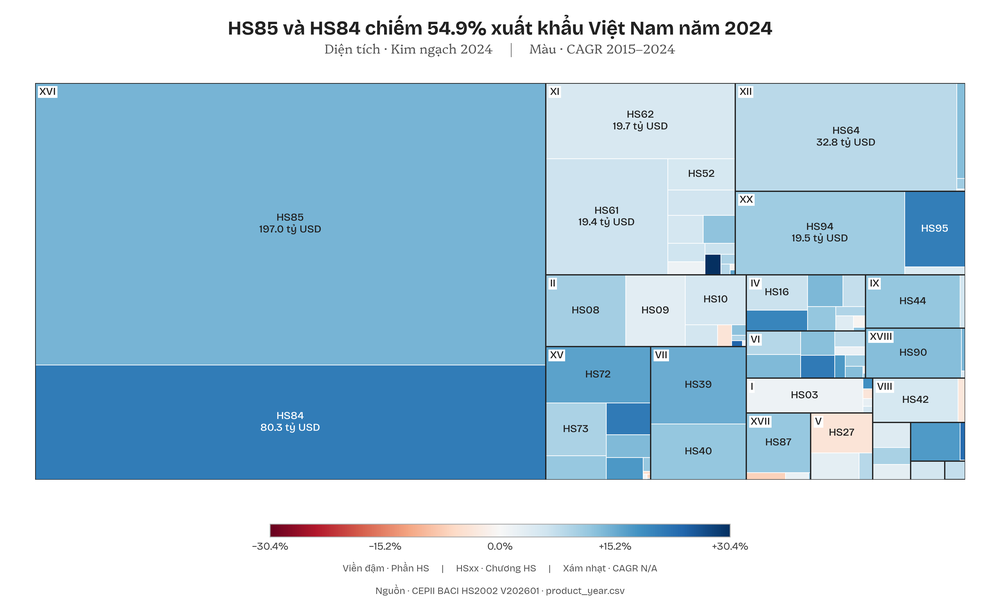

Phần HS,Chương,Tên chương,Xuất khẩu 2024,CAGR
"XVI · Máy móc, thiết bị điện",85,"Electrical machinery and equipment and parts thereof; sound recorders and reproducers, television image and sound recorders and reproducers, and parts and accessories of such articles.",197.0 tỷ USD,+14.1%
"XVI · Máy móc, thiết bị điện",84,"Nuclear reactors, boilers, machinery and mechanical appliances; parts thereof.",80.3 tỷ USD,+21.2%
"XII · Giày dép, mũ và phụ kiện",64,"Footwear, gaiters and the like; parts of such articles.",32.8 tỷ USD,+8.2%
XI · Dệt may,62,"Articles of apparel and clothing accessories, not knitted or crocheted.",19.7 tỷ USD,+4.9%
XX · Hàng hóa khác,94,"Furniture; bedding, mattresses, mattress supports, cushions and similar stuffed furnishings; lamps and lighting fittings, not elsewhere specified or included; illuminated signs, illuminated name-plates and the like; prefabricated buildings.",19.5 tỷ USD,+10.9%
XI · Dệt may,61,"Articles of apparel and clothing accessories, knitted or crocheted.",19.4 tỷ USD,+6.4%
VII · Nhựa và cao su,39,Plastics and articles thereof.,10.1 tỷ USD,+15.2%
XV · Kim loại cơ bản,72,Iron and steel.,8.1 tỷ USD,+16.3%
II · Sản phẩm thực vật,08,Edible fruit and nuts; peel of citrus fruit or melons.,7.9 tỷ USD,+10.3%
VII · Nhựa và cao su,40,Rubber and articles thereof.,7.3 tỷ USD,+11.7%


In [3]:
START_YEAR = 2015
END_YEAR = 2024
PRODUCT = ROOT / "data" / "clean" / "product_year.csv"
MAPPING = ROOT / "data" / "baci" / "data_clean" / "hs_classification.csv"
OUT = ROOT / "outputs" / "multivariate"

chapters, source_total = load_treemap(PRODUCT, MAPPING, START_YEAR, END_YEAR)
fig, parents, leaves = draw_treemap(chapters, START_YEAR, END_YEAR)

assert all(re.fullmatch(r"[0-9]{2}", code) for _, code, _, _, _ in chapters)
assert sum(row[3] for row in chapters) == source_total
assert set(leaves) == {code for _, code, _, usd, _ in chapters if usd > 0}
assert sum(usd for _, code, _, usd, _ in chapters if code in leaves) == source_total
section_totals = defaultdict(Decimal)
for section, code, _, usd, _ in chapters:
    section_totals[section] += usd
    if code in leaves:
        x, y, w, h = leaves[code]
        px, py, pw, ph = parents[section]
        assert px - 1e-12 <= x and py - 1e-12 <= y
        assert x + w <= px + pw + 1e-12 and y + h <= py + ph + 1e-12
        assert isclose(w * h / 1.8, float(usd / source_total), rel_tol=1e-9)
assert sum(section_totals.values()) == source_total
for section, (_, _, w, h) in parents.items():
    assert isclose(w * h / 1.8, float(section_totals[section] / source_total), rel_tol=1e-9)

print(f"{len(chapters)} chương thuộc {len(section_totals)} phần HS; {len(leaves)} ô có diện tích dương.")
missing = sum(cagr is None for _, _, _, _, cagr in chapters)
print(f"Tổng nguồn, tổng ô chương và tổng phần cùng bằng {source_total:,.0f} USD.")
print(f"CAGR không tính được: {missing} chương.")
OUT.mkdir(parents=True, exist_ok=True)
png, svg = [OUT / f"C08_treemap.{suffix}" for suffix in ("png", "svg")]
with apply_style(), rc_context({"svg.fonttype": "path"}):
    fig.savefig(png)
    fig.savefig(svg)
display(Image(filename=str(png), width=1000))
display_chapter_table(chapters, END_YEAR)

## Kết luận

- **HS85** là chương xuất khẩu lớn nhất năm 2024, đạt **197,0 tỷ USD** và tăng bình quân **14,1%/năm** so với năm 2015.
- **HS84** đạt **80,3 tỷ USD** và tăng bình quân **21,2%/năm**, nhanh hơn HS85. Hai chương cùng thuộc phần XVI và chiếm khoảng **54,9%** tổng xuất khẩu năm 2024.
- CAGR của 96 chương trải từ **−29,3%** ở HS43 đến **+30,4%** ở HS57. Bảng dưới hình cho phép dò giá trị của cả các chương có ô quá nhỏ để gắn nhãn.